<a href="https://colab.research.google.com/github/jessienatash4/SMT5_Data-Communication/blob/main/Program_Week_6_PQRST_dengan_DWT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Deteksi Gelombang PQRST pada Sinyal ECG menggunakan metode Discrete Wavelet Transform (DWT) dengan Wavelet Bebas**
Jessie Natasha
NRP. 5049241015

---



## **1. Instalasi dan mengambil dataset Kaggle**

In [5]:
!pip -q install kagglehub PyWavelets scipy

import os
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pywt

from scipy.signal import butter, sosfiltfilt, find_peaks

path = kagglehub.dataset_download(
    "devavratatripathy/ecg-dataset"
)

print("Dataset:", path)

for root, dirs, files in os.walk(path):
    for file in files:
        print(os.path.join(root, file))

Using Colab cache for faster access to the 'ecg-dataset' dataset.
Dataset: /kaggle/input/ecg-dataset
/kaggle/input/ecg-dataset/ecg.csv


## **2. Membaca dan memeriksa sinyal ECG**

In [6]:
csv_files = []

for root, dirs, files in os.walk(path):
    for file in files:
        if file.lower() == "ecg.csv":
            csv_files.append(os.path.join(root, file))

if not csv_files:
    raise FileNotFoundError("File ecg.csv tidak ditemukan.")

df = pd.read_csv(csv_files[0])

print("Ukuran dataset:", df.shape)
print("Kolom dataset:", df.columns.tolist())
display(df.head())

Ukuran dataset: (4997, 141)
Kolom dataset: ['-0.11252183', '-2.8272038', '-3.7738969', '-4.3497511', '-4.376041', '-3.4749863', '-2.1814082', '-1.8182865', '-1.2505219', '-0.47749208', '-0.36380791', '-0.49195659', '-0.42185509', '-0.30920086', '-0.4959387', '-0.34211867', '-0.35533627', '-0.36791303', '-0.31650279', '-0.41237405', '-0.47167181', '-0.41345783', '-0.36461703', '-0.44929829', '-0.47141866', '-0.42477658', '-0.46251673', '-0.55247236', '-0.47537519', '-0.6942', '-0.7018681', '-0.59381178', '-0.66068415', '-0.71383066', '-0.76980688', '-0.67228161', '-0.65367605', '-0.63940562', '-0.55930228', '-0.59167032', '-0.49322332', '-0.46305183', '-0.30164382', '-0.23273401', '-0.12505488', '-0.15394314', '-0.024357404', '-0.065608758', '0.034999258', '0.061935219', '0.07119542', '0.12392505', '0.10312371', '0.22522849', '0.12868305', '0.30248315', '0.25727621', '0.19635161', '0.17938297', '0.24472863', '0.34121687', '0.32820441', '0.40604169', '0.44660507', '0.42406823', '0.481512

,-0.11252183,-2.8272038,-3.7738969,-4.3497511,-4.376041,-3.4749863,-2.1814082,-1.8182865,-1.2505219,-0.47749208,...,0.79216787,0.93354122,0.79695779,0.57862066,0.2577399,0.22807718,0.12343082,0.92528624,0.19313742,1.0
0,-1.100878,-3.996840,-4.285843,-4.506579,-4.022377,-3.234368,-1.566126,-0.992258,-0.754680,0.042321,...,0.538356,0.656881,0.787490,0.724046,0.555784,0.476333,0.773820,1.119621,-1.436250,1.0
1,-0.567088,-2.593450,-3.874230,-4.584095,-4.187449,-3.151462,-1.742940,-1.490659,-1.183580,-0.394229,...,0.886073,0.531452,0.311377,-0.021919,-0.713683,-0.532197,0.321097,0.904227,-0.421797,1.0
2,0.490473,-1.914407,-3.616364,-4.318823,-4.268016,-3.881110,-2.993280,-1.671131,-1.333884,-0.965629,...,0.350816,0.499111,0.600345,0.842069,0.952074,0.990133,1.086798,1.403011,-0.383564,1.0
3,0.800232,-0.874252,-2.384761,-3.973292,-4.338224,-3.802422,-2.534510,-1.783423,-1.594450,-0.753199,...,1.148884,0.958434,1.059025,1.371682,1.277392,0.960304,0.971020,1.614392,1.421456,1.0
4,-1.507674,-3.574550,-4.478011,-4.408275,-3.321242,-2.105171,-1.481048,-1.301362,-0.498240,-0.286928,...,1.089068,0.983369,1.014124,0.952629,0.749326,1.007076,1.634990,1.493365,-0.783134,1.0


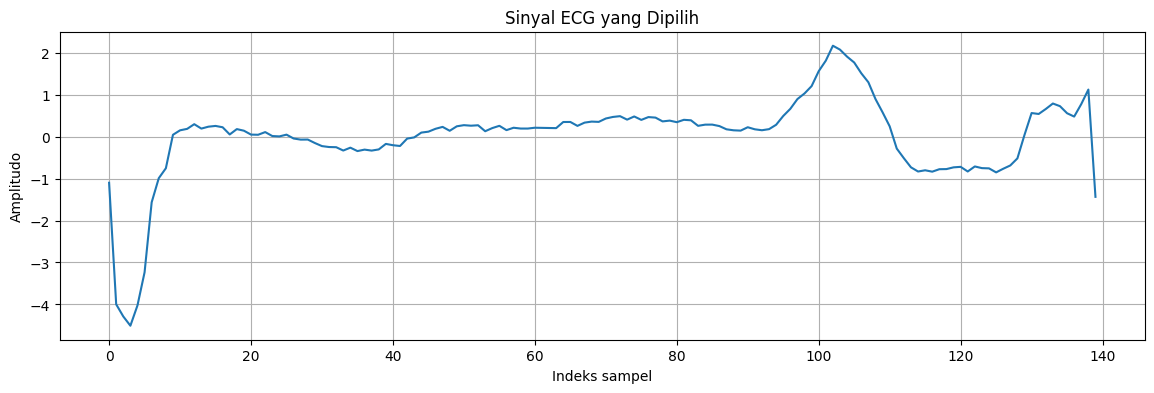

In [7]:
# Ubah sesuai kolom sinyal yang sebenarnya setelah memeriksa df.head().
# Contoh ini menggunakan kolom numerik pertama.
numeric_df = df.select_dtypes(include=np.number)

# Jika kolom terakhir merupakan label kelas, keluarkan dari sinyal.
signal_columns = list(numeric_df.columns)

ecg = numeric_df.iloc[0].to_numpy(dtype=float)

# Periksa apakah kolom terakhir adalah label biner.
if len(ecg) > 1 and ecg[-1] in (0, 1):
    ecg = ecg[:-1]

ecg = ecg[np.isfinite(ecg)]

FS = 360  # Ganti dengan frekuensi sampling sebenarnya jika sudah diketahui.

plt.figure(figsize=(14, 4))
plt.plot(np.arange(len(ecg)), ecg)
plt.title("Sinyal ECG yang Dipilih")
plt.xlabel("Indeks sampel")
plt.ylabel("Amplitudo")
plt.grid(True)
plt.show()

## **3. Preprocessing dan DWT**

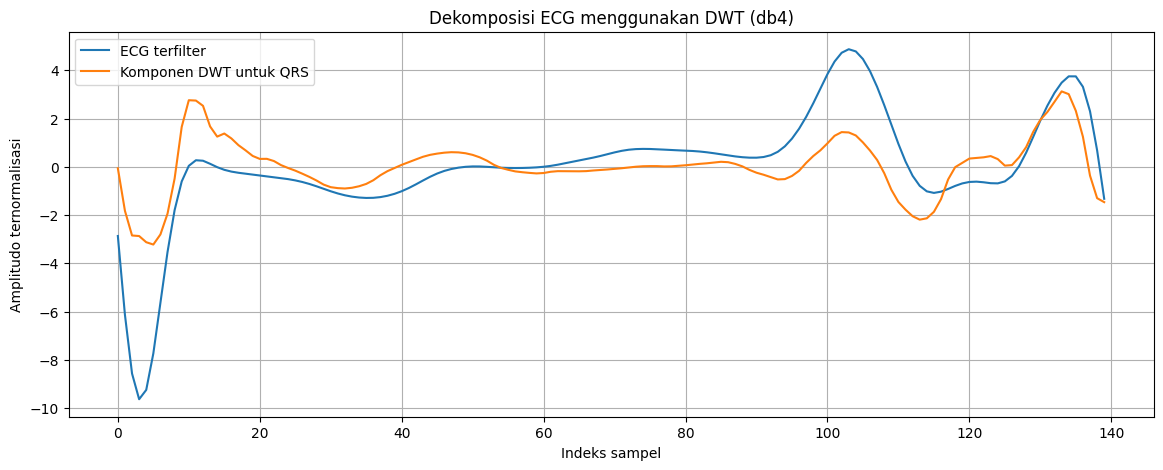

In [8]:
# Pilihan wavelet
WAVELET = "db4"

# Preprocessing: band-pass filter 0.5-40 Hz
if FS <= 80:
    raise ValueError("FS harus lebih besar dari 80 Hz.")

sos = butter(
    3, [0.5, 40],
    btype="bandpass",
    fs=FS,
    output="sos"
)

ecg_filtered = sosfiltfilt(sos, ecg)

# Normalisasi robust
median_ecg = np.median(ecg_filtered)
mad = np.median(np.abs(ecg_filtered - median_ecg))
ecg_norm = (
    ecg_filtered - median_ecg
) / (1.4826 * mad + 1e-12)

# Dekomposisi DWT
wavelet = pywt.Wavelet(WAVELET)
level = min(
    8,
    pywt.dwt_max_level(len(ecg_norm), wavelet.dec_len)
)

if level < 1:
    raise ValueError("Sinyal terlalu pendek untuk DWT.")

coeffs = pywt.wavedec(
    ecg_norm, WAVELET, level=level
)

# Rekonstruksi komponen detail DWT pada pita QRS
qrs_signal = np.zeros_like(ecg_norm)

for j in range(1, level + 1):
    f_low = FS / (2 ** (j + 1))
    f_high = FS / (2 ** j)

    if f_high >= 5 and f_low <= 25:
        isolated = [np.zeros_like(c) for c in coeffs]
        isolated[-j] = coeffs[-j]

        reconstructed = pywt.waverec(
            isolated, WAVELET
        )
        qrs_signal += reconstructed[:len(ecg_norm)]

plt.figure(figsize=(14, 5))
plt.plot(ecg_norm, label="ECG terfilter")
plt.plot(qrs_signal, label="Komponen DWT untuk QRS")
plt.title(f"Dekomposisi ECG menggunakan DWT ({WAVELET})")
plt.xlabel("Indeks sampel")
plt.ylabel("Amplitudo ternormalisasi")
plt.legend()
plt.grid(True)
plt.show()

## **4. Deteksi gelombang R**

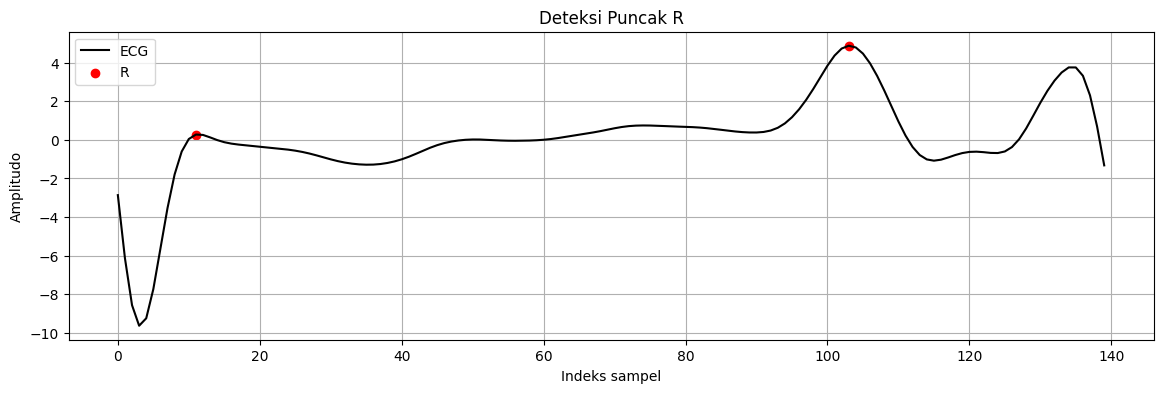

Jumlah puncak R: 2


In [9]:
energy = qrs_signal ** 2

window_energy = max(1, int(0.08 * FS))
kernel = np.ones(window_energy) / window_energy
energy_smooth = np.convolve(
    energy, kernel, mode="same"
)

threshold = (
    np.median(energy_smooth)
    + 0.5 * np.std(energy_smooth)
)

candidates, _ = find_peaks(
    energy_smooth,
    distance=int(0.25 * FS),
    height=threshold
)

R_candidates = []

search_radius = int(0.08 * FS)

for idx in candidates:
    left = max(0, idx - search_radius)
    right = min(len(ecg_norm), idx + search_radius + 1)

    r_idx = left + np.argmax(ecg_norm[left:right])
    R_candidates.append(r_idx)

# Gabungkan kandidat yang terlalu dekat.
R_candidates = sorted(set(R_candidates))
R = []

for idx in R_candidates:
    if not R or idx - R[-1] >= int(0.25 * FS):
        R.append(idx)
    elif ecg_norm[idx] > ecg_norm[R[-1]]:
        R[-1] = idx

R = np.asarray(R, dtype=int)

plt.figure(figsize=(14, 4))
plt.plot(ecg_norm, color="black", label="ECG")
plt.scatter(R, ecg_norm[R], color="red", label="R")
plt.title("Deteksi Puncak R")
plt.xlabel("Indeks sampel")
plt.ylabel("Amplitudo")
plt.legend()
plt.grid(True)
plt.show()

print("Jumlah puncak R:", len(R))

## **5. Deteksi P, Q, S, dan T**

In [10]:
P, Q, S, T = [], [], [], []

for i, r in enumerate(R):

    # Q: 100-10 ms sebelum R
    q1 = max(0, r - int(0.10 * FS))
    q2 = max(q1 + 1, r - int(0.01 * FS))
    q2 = min(q2, len(ecg_norm))

    Q.append(
        q1 + np.argmin(ecg_norm[q1:q2])
        if q2 > q1 else np.nan
    )

    # S: 10-100 ms setelah R
    s1 = min(len(ecg_norm) - 1, r + int(0.01 * FS))
    s2 = min(len(ecg_norm), r + int(0.10 * FS))

    S.append(
        s1 + np.argmin(ecg_norm[s1:s2])
        if s2 > s1 else np.nan
    )

    # P: 250-100 ms sebelum R
    p1 = max(0, r - int(0.25 * FS))
    p2 = max(p1 + 1, r - int(0.10 * FS))

    if p2 > p1:
        segment = ecg_norm[p1:p2]
        P.append(
            p1 + np.argmax(
                np.abs(segment - np.median(segment))
            )
        )
    else:
        P.append(np.nan)

    # T: 100-450 ms setelah R
    t1 = min(len(ecg_norm) - 1, r + int(0.10 * FS))
    t2 = min(len(ecg_norm), r + int(0.45 * FS))

    if i + 1 < len(R):
        t2 = min(t2, R[i + 1] - int(0.08 * FS))

    if t2 > t1:
        segment = ecg_norm[t1:t2]
        T.append(
            t1 + np.argmax(
                np.abs(segment - np.median(segment))
            )
        )
    else:
        T.append(np.nan)

P = np.asarray(P, dtype=float)
Q = np.asarray(Q, dtype=float)
S = np.asarray(S, dtype=float)
T = np.asarray(T, dtype=float)

## **6. Visualisasi hasil deteksi PQRST**

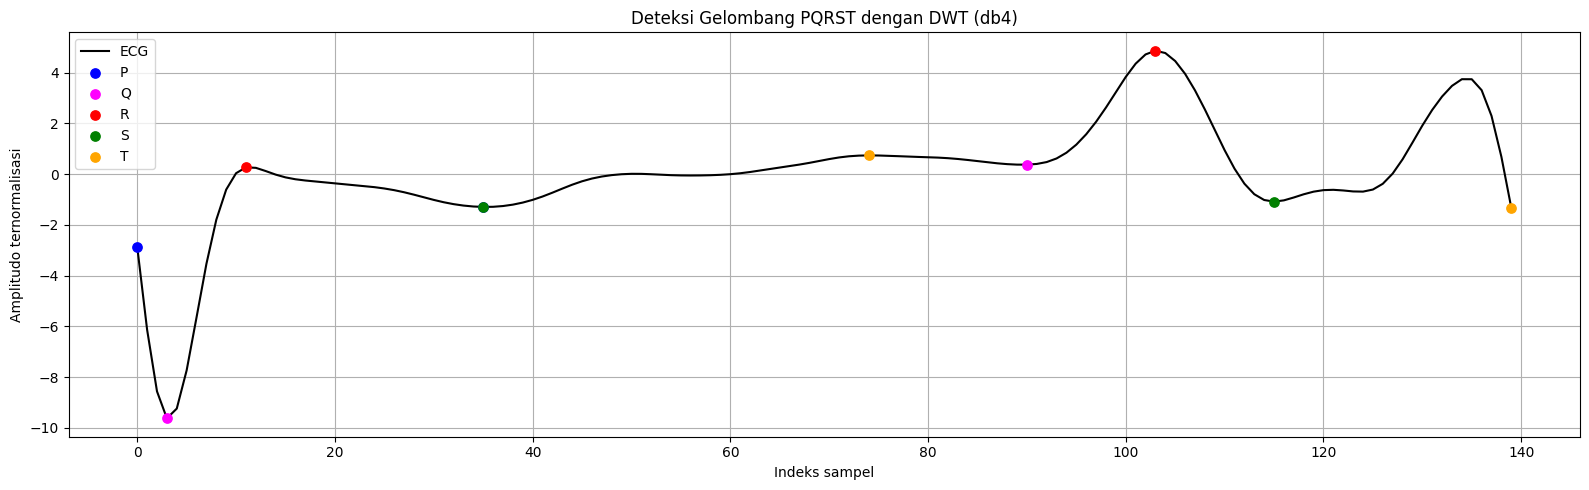

In [11]:
plt.figure(figsize=(16, 5))
plt.plot(ecg_norm, color="black", label="ECG")

waves = [
    ("P", P, "blue"),
    ("Q", Q, "magenta"),
    ("R", R.astype(float), "red"),
    ("S", S, "green"),
    ("T", T, "orange")
]

for name, indices, color in waves:
    valid = np.isfinite(indices)
    idx = indices[valid].astype(int)

    plt.scatter(
        idx, ecg_norm[idx],
        color=color, s=45, label=name, zorder=3
    )

plt.title(f"Deteksi Gelombang PQRST dengan DWT ({WAVELET})")
plt.xlabel("Indeks sampel")
plt.ylabel("Amplitudo ternormalisasi")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## **7. Tabel hasil dan ekspor CSV**

In [12]:
results = pd.DataFrame({
    "P_index": P,
    "Q_index": Q,
    "R_index": R,
    "S_index": S,
    "T_index": T
})

for name in ["P", "Q", "R", "S", "T"]:
    results[f"{name}_time_s"] = (
        results[f"{name}_index"] / FS
    )

display(results)

results.to_csv(
    "hasil_deteksi_PQRST.csv",
    index=False
)

from google.colab import files
files.download("hasil_deteksi_PQRST.csv")

,P_index,Q_index,R_index,S_index,T_index,P_time_s,Q_time_s,R_time_s,S_time_s,T_time_s
0,0.0,3.0,11,35.0,74.0,0.000000,0.008333,0.030556,0.097222,0.205556
1,35.0,90.0,103,115.0,139.0,0.097222,0.250000,0.286111,0.319444,0.386111


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>